# Actividad 3. Transferencia y ajuste fino para reconocer gestos

David Santiago Iriarte Zamora y Jose Adrian Trochez Cuellar · Grupo 12

Usamos fotografías públicas de papel, piedra y tijera. Comparamos una base MobileNetV2 congelada con ajuste fino parcial, y evaluamos un cambio de dominio con imágenes sintéticas. El informe PDF tiene cinco páginas. Este notebook y `src/` forman el código completo.

## 1. Entorno y reproducción

El modo normal utiliza modelos y datos preparados incluidos. Para repetir desde las fuentes, activamos `RECONSTRUIR_DATOS`; para entrenar de nuevo, `REENTRENAR`. La descarga requiere internet. El entrenamiento usa CPU y conserva las semillas y particiones.

In [1]:
from pathlib import Path
import sys, json, os
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir() and (p / 'datos').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache/matplotlib'))
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '3')
import numpy as np
import pandas as pd
from IPython.display import display, Image, Code
pd.set_option('display.max_columns', 20)
print('Carpeta de trabajo:', ROOT.name)


Carpeta de trabajo: Actividad 3


In [2]:
RECONSTRUIR_DATOS = False
REENTRENAR = False
if RECONSTRUIR_DATOS:
    from descargar_datos import descargar
    from preparar_datos import preparar
    descargar()
    preparar()
import entrenar_a3 as a3
a3.configurar()
if REENTRENAR:
    from preparar_pesos import preparar
    preparar()
    a3.run(force=True)
RES = ROOT / 'resultados'
config = json.loads((RES/'config_A3.json').read_text())
display(config['versiones'])


Matplotlib is building the font cache; this may take a moment.


{'python': '3.12.11',
 'tensorflow': '2.21.0',
 'keras': '3.15.1',
 'numpy': '2.5.3',
 'plataforma': 'macOS-26.6.2-arm64-arm-64bit',
 'cpu_logicos': 12,
 'dispositivo': 'CPU'}

## 2. Datos y prevención de fugas

Usamos 2.188 fotografías (DrGFreeman, CC BY-SA 4.0). Agrupamos tres pares casi duplicados y usamos 10 pliegues estratificados por grupo: 6/2/2. No conocemos identidades de personas ni sesiones. Los 372 CGI de Moroney (CC BY 2.0) quedan fuera de toda selección. Los conteos provienen de los archivos, no del README de origen.

In [3]:
import hashlib
manifest = pd.read_csv(RES/'particiones.csv')
print(manifest.columns.tolist())
display(json.loads((RES/'datos_resumen.json').read_text()))
assert hashlib.sha256((RES/'particiones.csv').read_bytes()).hexdigest() == config['sha256_particiones']
data = {p: np.load(ROOT/f'datos/{p}_128.npz') for p in ['train','val','test','externo']}
for a,b in [('train','val'),('train','test'),('val','test')]:
    assert not set(data[a]['groups']) & set(data[b]['groups'])
for name,d in data.items():
    assert d['X'].shape[1:] == (128,128,3)
    assert d['X'].dtype == np.uint8
    print(name, d['X'].shape, np.bincount(d['y']))


['path', 'clase', 'label', 'alto', 'ancho', 'sha256', 'pixel_sha256', 'grupo', 'excluir', 'fold', 'particion']


{'n_original': 2188,
 'n_limpio': 2188,
 'excluidos': 0,
 'grupos': 2185,
 'pares_similares': 3,
 'umbral_corr': 0.985,
 'umbral_dhash': 4,
 'particiones': {'paper': {'test': 143, 'train': 427, 'val': 142},
  'rock': {'test': 144, 'train': 437, 'val': 145},
  'scissors': {'test': 150, 'train': 450, 'val': 150}},
 'sha256_particiones': '140bd2295f70727ee32f5f5c7a8e355774b7ae1068744c2ea850b08dcfa46c24',
 'limite': 'No existen identificadores de persona o sesión. Agrupar semejanza visual reduce fugas, pero no demuestra independencia entre sujetos.'}

train (1314, 128, 128, 3) [427 437 450]
val (437, 128, 128, 3) [142 145 150]
test (437, 128, 128, 3) [143 144 150]


externo (372, 128, 128, 3) [124 124 124]


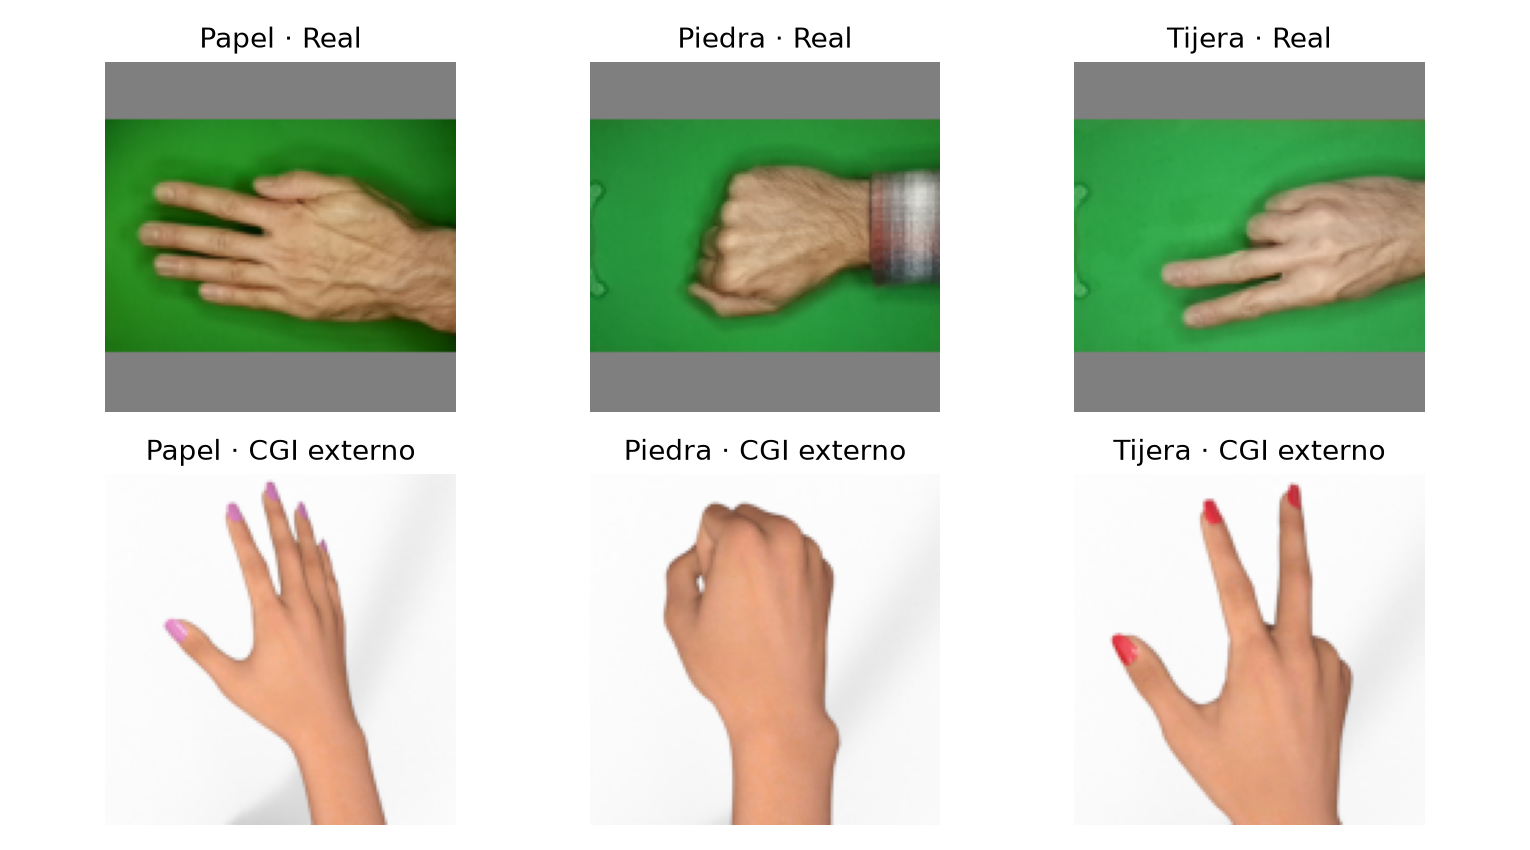

In [4]:
display(Image(filename=str(ROOT/'figuras/datos_dominios.png')))

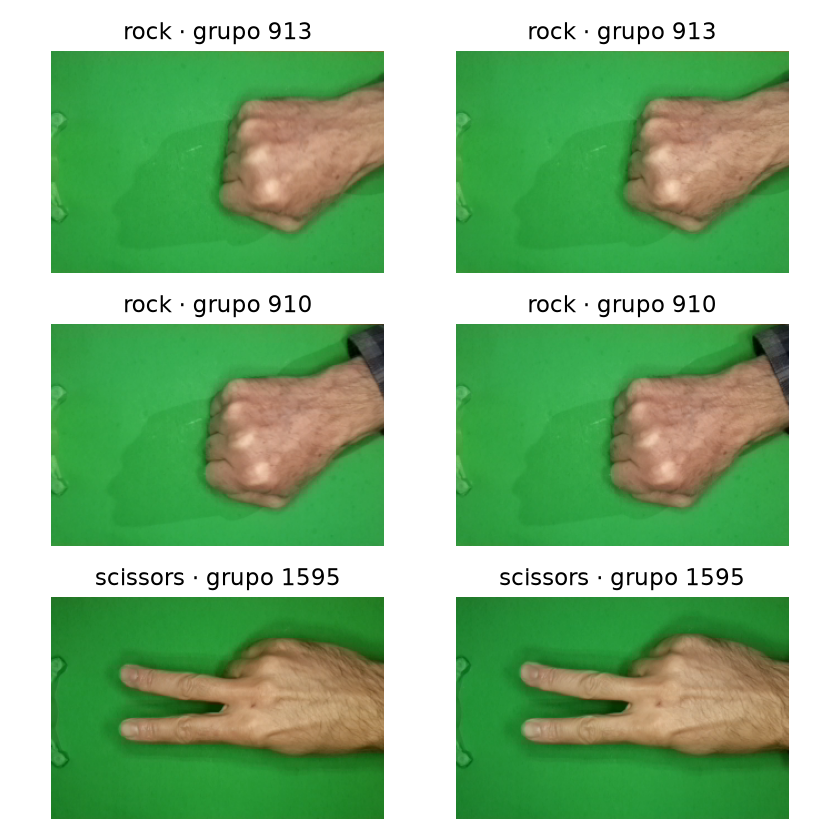

In [5]:
display(Image(filename=str(ROOT/'figuras/grupos_visuales.png')))

**Lectura:** las fotografías reales comparten fondo verde y una orientación predominante. Las imágenes CGI tienen fondo blanco y una orientación diferente. Agrupar semejanza visual evita compartir los pares encontrados, pero no garantiza separación por persona.

## 3. Preprocesamiento, arquitectura y aumentación

Conservamos la proporción a 128 × 128 con relleno 127. El modelo normaliza a [−1, 1]. GAP convierte 4 × 4 × 1.280 en 1.280 valores; la cabeza de tres clases tiene 3.843 parámetros. No aumentamos validación ni prueba. El código siguiente es la implementación utilizada, disponible íntegra en `src/entrenar_a3.py`.

In [6]:
import inspect
for fn in [a3.modelo_nuevo, a3.datasets]:
    display(Code(inspect.getsource(fn), language='python'))
model, base = a3.modelo_nuevo()
model.summary()
assert model.count_params() == 414051
assert sum(np.prod(v.shape) for v in model.trainable_weights) == 3843


def modelo_nuevo():
    base=tf.keras.applications.MobileNetV2(input_shape=(128,128,3),alpha=.35,include_top=False,weights=None)
    base.load_weights(DATA/'mobilenetv2_035_128_imagenet.weights.h5')
    base.trainable=False
    inp=tf.keras.Input((128,128,3),name='rgb_0_255')
    x=tf.keras.layers.Rescaling(1/127.5,offset=-1,name='normalizacion_imagenet')(inp)
    x=base(x,training=False)
    x=tf.keras.layers.GlobalAveragePooling2D(name='promedio_espacial')(x)
    x=tf.keras.layers.Dropout(.2,name='dropout')(x)
    out=tf.keras.layers.Dense(3,name='logits')(x)
    return tf.keras.Model(inp,out,name='clasificador_rps'),base

def datasets(seed):
    x,y=cargar('train'); xv,yv=cargar('val')
    L=tf.keras.layers
    aug=tf.keras.Sequential([L.RandomFlip('horizontal',seed=seed),L.RandomRotation(.05,fill_mode='reflect',seed=seed+1),
        L.RandomTranslation(.05,.05,fill_mode='reflect',seed=seed+2),L.RandomZoom(.1,fill_mode='reflect',seed=seed+3),
        L.RandomContrast(.15,seed=seed+4),L.RandomBrightness(.1,value_range=(0,255),seed=seed+5)])
    ds=tf.data.Dataset.from_tensor_slices((x,y)).shuffle(len(y),seed=seed,reshuffle_each_iteration=True).batch(PARAMS['batch'])
    ds=ds.map(lambda a,b:(aug(a,training=True),b),num_parallel_calls=1).prefetch(1)
    opts=tf.data.Options();opts.threading.private_threadpool_size=2;opts.experimental_deterministic=True
    return ds.with_options(opts),tf.data.Dataset.from_tensor_slices((xv,yv)).batch(64).with_options(opts)

Model: "clasificador_rps"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rgb_0_255 (InputLayer)          │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacion_imagenet          │ (None, 128, 128, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_0.35_128            │ (None, 4, 4, 1280)     │       410,208 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ promedio_espacial               │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 414,051 (1.58 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 410,208 (1.56 MB)

## 4. Congelamiento, ajuste fino y selección

Adam con entropía cruzada sobre logits usa LR 10⁻³ en la cabeza y 10⁻⁴ desde `block_13_expand`. Mantenemos BatchNormalization congelada y la base en modo inferencia; sus convoluciones habilitadas sí reciben gradientes. Recompilamos al cambiar capas entrenables. Cada etapa restaura su mejor pérdida de validación. No comparamos presupuestos idénticos: el ajuste fino continúa y agrega entrenamiento.

In [7]:
display(Code(inspect.getsource(a3.entrenar_etapa), language='python'))
display(Code(inspect.getsource(a3.run), language='python'))
histories=[]
for seed in config['semillas_ejecutadas']:
    control=json.loads((RES/f'control_finetuning_s{seed}.json').read_text())
    assert control['cambio_L2_block13'] > 0 and control['batchnorm_entrenables'] == 0
    for stage in ['congelada','finetuning']:
        h=json.loads((RES/f'historia_{stage}_s{seed}.json').read_text())
        histories.append({k:h[k] for k in ['seed','stage','entrenables','lr','mejor_epoca','total_s']})
display(pd.DataFrame(histories))
display(pd.read_csv(RES/'seleccion_validacion.csv'))
print('Etapa elegida:', config['elegido'])


def entrenar_etapa(model,train,val,seed,stage,epochs,lr):
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),metrics=['accuracy'])
    reg=Registro(seed,stage)
    start=time.perf_counter()
    hist=model.fit(train,validation_data=val,epochs=epochs,verbose=0,shuffle=False,callbacks=[reg,
        tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=PARAMS['paciencia'],min_delta=1e-4,restore_best_weights=True)])
    elapsed=time.perf_counter()-start
    model.save(MODELS/f'{stage}_s{seed}.keras')
    record={'history':hist.history,'epocas_s':reg.times,'total_s':elapsed,'mejor_epoca':int(np.argmin(hist.history['val_loss'])+1),
            'parametros':model.count_params(),'entrenables':int(sum(np.prod(v.shape) for v in model.trainable_weights)),
            'lr':lr,'seed':seed,'stage':stage}
    (RES/f'historia_{stage}_s{seed}.json').write_text(json.dumps(record,indent=2))
    return record

def run(seeds=None,force=False):
    configurar();seeds=seeds or PARAMS['semillas']
    (RES/'protocolo_previo.json').write_text(json.dumps(PARAMS,indent=2,ensure_ascii=False))
    val_metrics=[]
    for seed in seeds:
        tf.keras.backend.clear_session();tf.keras.utils.set_random_seed(seed)
        train,val=datasets(seed)
        if force or not (MODELS/f'congelada_s{seed}.keras').exists():
            model,base=modelo_nuevo()
            before=[v.numpy().copy() for v in base.weights]
            entrenar_etapa(model,train,val,seed,'congelada',PARAMS['epocas_congelada'],PARAMS['lr_congelada'])
            assert all(np.array_equal(a,b.numpy()) for a,b in zip(before,base.weights)), 'La base congelada cambió'
        model=tf.keras.models.load_model(MODELS/f'congelada_s{seed}.keras')
        if force or not (MODELS/f'finetuning_s{seed}.keras').exists():
            base=next(l for l in model.layers if isinstance(l,tf.keras.Model))
            base.trainable=True
            reached=False
            for layer in base.layers:
                if layer.name==PARAMS['fine_desde']:reached=True
                layer.trainable=reached and not isinstance(layer,tf.keras.layers.BatchNormalization)
            assert reached
            watched=base.get_layer('block_13_expand').get_weights()[0].copy()
            rec=entrenar_etapa(model,train,val,seed,'finetuning',PARAMS['epocas_finetuning'],PARAMS['lr_finetuning'])
            delta=float(np.linalg.norm(base.get_layer('block_13_expand').get_weights()[0]-watched))
            assert delta>0,'No hubo ajuste fino'
            (RES/f'control_finetuning_s{seed}.json').write_text(json.dumps({'cambio_L2_block13':delta,'batchnorm_entrenables':sum(l.trainable for l in base.layers if isinstance(l,tf.keras.layers.BatchNormalization))}))
        xv,yv=cargar('val')
        for stage in ['congelada','finetuning']:
            model=tf.keras.models.load_model(MODELS/f'{stage}_s{seed}.keras');p=probabilidades(model,xv)
            val_metrics.append({'stage':stage,'seed':seed,'f1_macro':float(f1_score(yv,p.argmax(1),average='macro')),'accuracy':float(accuracy_score(yv,p.argmax(1)))})
    vals=pd.DataFrame(val_metrics);vals.to_csv(RES/'seleccion_validacion.csv',index=False)
    means=vals.groupby('stage').f1_macro.mean()
    elegido='finetuning' if means['finetuning']>means['congelada']+.001 else 'congelada'
    config={'params':PARAMS,'semillas_ejecutadas':seeds,'elegido':elegido,'semilla_despliegue':42,
            'versiones':{'python':platform.python_version(),'tensorflow':tf.__version__,'keras':tf.keras.__version__,
            'numpy':np.__version__,'plataforma':platform.platform(),'cpu_logicos':os.cpu_count(),'dispositivo':'CPU'},
            'sha256_particiones':hashlib.sha256((RES/'particiones.csv').read_bytes()).hexdigest(),
            'sha256_pesos_preentrenados':hashlib.sha256((DATA/'mobilenetv2_035_128_imagenet.weights.h5').read_bytes()).hexdigest()}
    # Decisión persistida ANTES de evaluar test y externo; no se selecciona semilla por prueba.
    (RES/'config_A3.json').write_text(json.dumps(config,indent=2,ensure_ascii=False))
    print('Seleccionado por validación:',elegido,flush=True)
    results=[];perclass=[]
    for seed in seeds:
        for stage in ['congelada','finetuning']:
            model=tf.keras.models.load_model(MODELS/f'{stage}_s{seed}.keras')
            for part in ['train','val','test','externo']:
                x,y=cargar(part);p=probabilidades(model,x);yp=p.argmax(1)
                np.savez_compressed(RES/f'pred_{stage}_s{seed}_{part}.npz',y=y,prob=p)
                results.append({'stage':stage,'seed':seed,'particion':part,'n':len(y),
                                'accuracy':accuracy_score(y,yp),'f1_macro':f1_score(y,yp,average='macro')})
                if part in ['test','externo']:
                    report=classification_report(y,yp,target_names=CLASES,output_dict=True,zero_division=0)
                    for c in CLASES:perclass.append({'stage':s

,seed,stage,entrenables,lr,mejor_epoca,total_s
0,42,congelada,3843,0.0010,10,23.812768
1,42,finetuning,306611,0.0001,5,24.018998
2,7,congelada,3843,0.0010,9,23.334710
3,7,finetuning,306611,0.0001,6,26.778988
4,2026,congelada,3843,0.0010,10,26.076184
5,2026,finetuning,306611,0.0001,5,25.316118


,stage,seed,f1_macro,accuracy
0,congelada,42,0.997677,0.997712
1,finetuning,42,1.000000,1.000000
2,congelada,7,1.000000,1.000000
3,finetuning,7,1.000000,1.000000
4,congelada,2026,0.997677,0.997712
5,finetuning,2026,1.000000,1.000000


Etapa elegida: finetuning


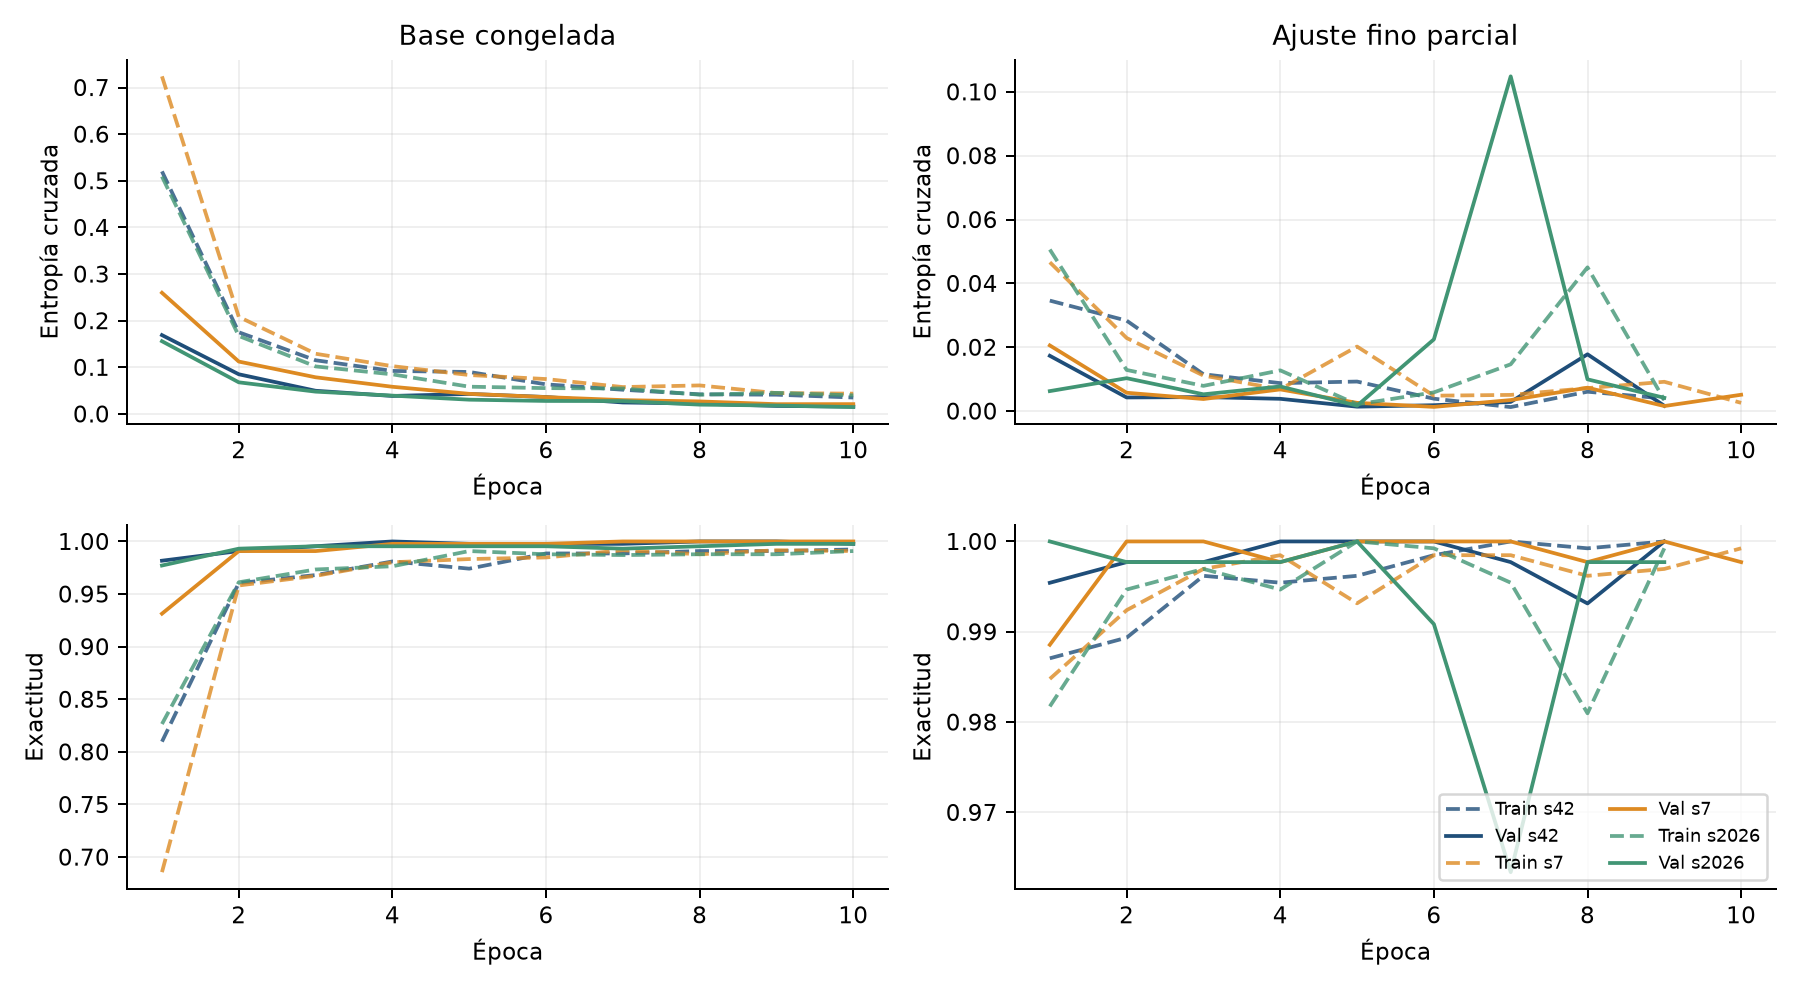

In [8]:
display(Image(filename=str(ROOT/'figuras/curvas.png')))

**Lectura:** la referencia converge rápido. El ajuste fino oscila en algunas épocas, por lo que restauramos el mejor punto. El F1 macro medio de validación pasa de 0,99845 a 1,0000 y cumple el margen prefijado de 0,001. La semilla 42 se fijó antes de prueba; no representa un ensamble ni la mejor semilla seleccionada a posteriori.

## 5. Evaluación global y por clase

In [9]:
from analizar_a3 import run as analizar
analizar()
display(pd.read_csv(RES/'resumen_metricas.csv'))
perclass=pd.read_csv(RES/'resumen_por_clase.csv')
display(perclass)
globales=perclass.groupby(['stage','particion'])[['precision','recall','f1-score']].mean()
display(globales)


     stage particion  accuracy  accuracy_sd       f1    f1_sd
 congelada   externo  0.627240     0.027589 0.518995 0.037148
 congelada      test  1.000000     0.000000 1.000000 0.000000
 congelada     train  0.996195     0.000761 0.996167 0.000765
 congelada       val  0.998474     0.001321 0.998451 0.001341
finetuning   externo  0.577957     0.060767 0.474309 0.043948
finetuning      test  1.000000     0.000000 1.000000 0.000000
finetuning     train  0.999746     0.000439 0.999746 0.000439
finetuning       val  1.000000     0.000000 1.000000 0.000000
{'wilson_test_437_aciertos': [0.9912860763346294, 1.0], 'mayoritaria_accuracy': 0.34324942791762014, 'mayoritaria_f1': 0.17035775127768313, 'limite_IC': 'Wilson orientativo por imagen; no corrige dependencia por sujetos no identificados.', 'bootstrap': [{'particion': 'test', 'delta_accuracy': 0.0, 'IC95_inf': 0.0, 'IC95_sup': 0.0, 'grupos': 437}, {'particion': 'externo', 'delta_accuracy': -0.0492831541218638, 'IC95_inf': -0.11740591397849

,stage,particion,accuracy,accuracy_sd,f1,f1_sd
0,congelada,externo,0.627240,0.027589,0.518995,0.037148
1,congelada,test,1.000000,0.000000,1.000000,0.000000
2,congelada,train,0.996195,0.000761,0.996167,0.000765
3,congelada,val,0.998474,0.001321,0.998451,0.001341
4,finetuning,externo,0.577957,0.060767,0.474309,0.043948
5,finetuning,test,1.000000,0.000000,1.000000,0.000000
6,finetuning,train,0.999746,0.000439,0.999746,0.000439
7,finetuning,val,1.000000,0.000000,1.000000,0.000000


,stage,particion,clase,precision,recall,f1-score,support
0,congelada,externo,paper,0.594768,0.959677,0.731667,124.0
1,congelada,externo,rock,0.667976,0.887097,0.758925,124.0
2,congelada,externo,scissors,0.666667,0.034946,0.066393,124.0
3,congelada,test,paper,1.000000,1.000000,1.000000,143.0
4,congelada,test,rock,1.000000,1.000000,1.000000,144.0
5,congelada,test,scissors,1.000000,1.000000,1.000000,150.0
6,finetuning,externo,paper,0.478013,0.989247,0.641304,124.0
7,finetuning,externo,rock,0.865961,0.744624,0.781622,124.0
8,finetuning,externo,scissors,0.000000,0.000000,0.000000,124.0
9,finetuning,test,paper,1.000000,1.000000,1.000000,143.0


precision    recall  f1-score
stage      particion                               
congelada  externo     0.643137  0.627240  0.518995
           test        1.000000  1.000000  1.000000
finetuning externo     0.447991  0.577957  0.474309
           test        1.000000  1.000000  1.000000

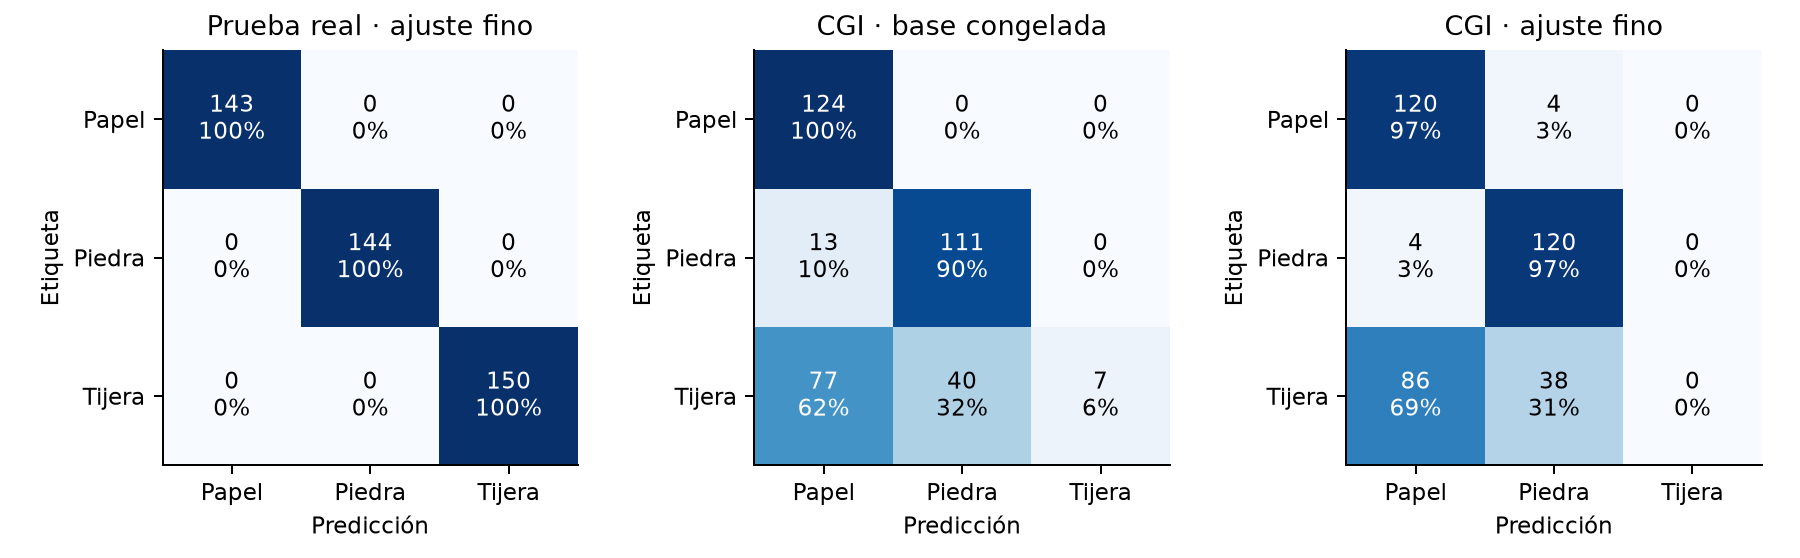

In [10]:
display(Image(filename=str(ROOT/'figuras/confusion.png')))

**Lectura:** ambos modelos aciertan 437/437 en prueba real, con precision, recall y F1 iguales a 1 por clase. La referencia trivial mayoritaria solo logra 34,32 %. No observamos mejora de prueba por ajuste fino. En CGI la exactitud media baja de 62,72 % a 57,80 %, y el recall de tijera del ajuste fino es cero en las tres semillas. El buen resultado de prueba se limita a imágenes similares a las de entrenamiento.

## 6. Errores e incertidumbre

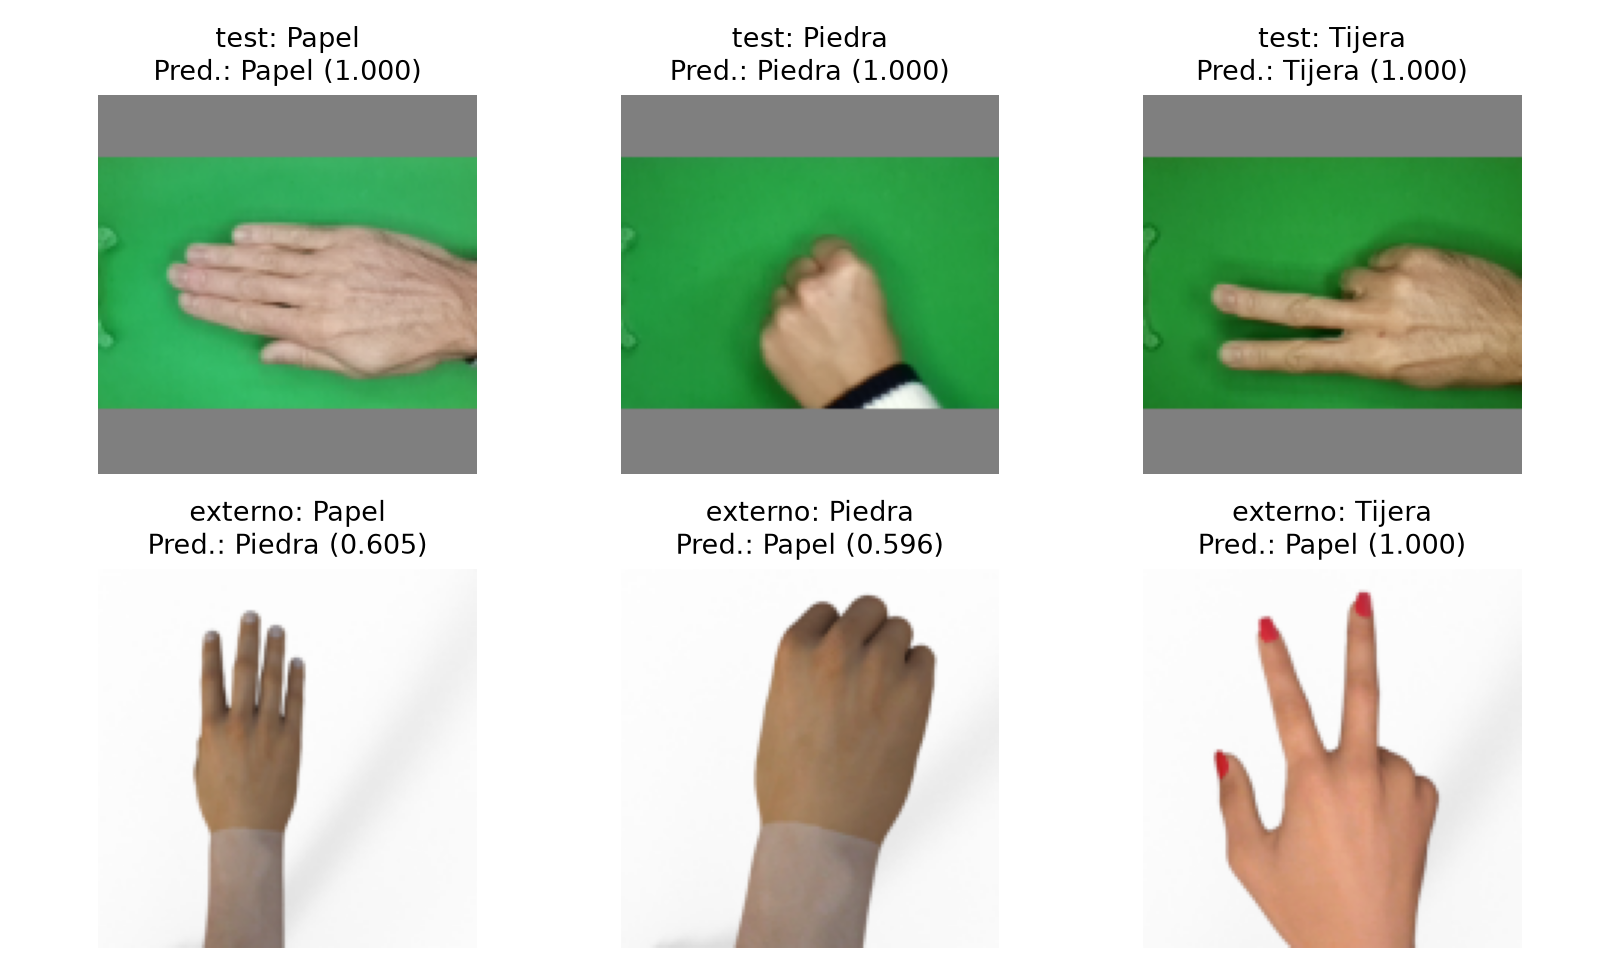

In [11]:
display(Image(filename=str(ROOT/'figuras/aciertos_errores.png')))

In [12]:
display(pd.read_csv(RES/'bootstrap.csv'))
display(json.loads((RES/'analisis.json').read_text()))
# Confirmación independiente de las métricas principales desde predicciones guardadas.
from sklearn.metrics import accuracy_score, classification_report
for stage in ['congelada','finetuning']:
    pred=np.load(RES/f'pred_{stage}_s42_test.npz')
    assert np.array_equal(pred['y'], data['test']['y'])
    assert accuracy_score(pred['y'],pred['prob'].argmax(1)) == 1
print(classification_report(np.load(RES/'pred_finetuning_s42_externo.npz')['y'],
      np.load(RES/'pred_finetuning_s42_externo.npz')['prob'].argmax(1),
      target_names=['Papel','Piedra','Tijera'],zero_division=0))


,particion,delta_accuracy,IC95_inf,IC95_sup,grupos
0,test,0.000000,0.000000,0.000000,437
1,externo,-0.049283,-0.117406,0.009857,12


{'wilson_test_437_aciertos': [0.9912860763346294, 1.0],
 'mayoritaria_accuracy': 0.34324942791762014,
 'mayoritaria_f1': 0.17035775127768313,
 'limite_IC': 'Wilson orientativo por imagen; no corrige dependencia por sujetos no identificados.',
 'bootstrap': [{'particion': 'test',
   'delta_accuracy': 0.0,
   'IC95_inf': 0.0,
   'IC95_sup': 0.0,
   'grupos': 437},
  {'particion': 'externo',
   'delta_accuracy': -0.0492831541218638,
   'IC95_inf': -0.11740591397849465,
   'IC95_sup': 0.00985663082437276,
   'grupos': 12}]}

              precision    recall  f1-score   support

       Papel       0.57      0.97      0.72       124
      Piedra       0.74      0.97      0.84       124
      Tijera       0.00      0.00      0.00       124

    accuracy                           0.65       372
   macro avg       0.44      0.65      0.52       372
weighted avg       0.44      0.65      0.52       372



**Lectura:** escogimos aciertos y errores de alta confianza por clase, no una muestra aleatoria. Una tijera CGI se predice como papel con confianza redondeada a 1. El cambio de orientación, fondo y textura ocurre simultáneamente; no aislamos causalidad. Wilson [99,13 %; 100 %] en prueba supone independencia por imagen, no verificada por persona. El bootstrap CGI agrupa 12 secuencias: Δ = −4,93 pp, IC 95 % [−11,74; 0,99], con evidencia insuficiente para afirmar una diferencia estable.

## 7. Conclusiones

La transferencia resuelve el dominio de origen con una cabeza pequeña. El ajuste fino funciona técnicamente, pero no mejora la prueba real y no corrige el cambio de dominio. Para ampliar el uso necesitamos fondos, orientaciones y personas nuevas, partición por sujeto y un conjunto externo real. Conservamos pesos, manifiestos, predicciones y código para revisar cada resultado.

## Referencias

DrGFreeman. (s. f.). *Rock-Paper-Scissors image dataset* [Conjunto de datos]. GitHub. https://github.com/DrGFreeman/rps-cv-data-science

Moroney, L. (s. f.). *Datasets: Rock, Paper, Scissors* [Conjunto de datos]. https://laurencemoroney.com/datasets.html

Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., & Chen, L.-C. (2018). MobileNetV2: Inverted residuals and linear bottlenecks. *Proceedings of CVPR*, 4510-4520. https://openaccess.thecvf.com/content_cvpr_2018/html/Sandler_MobileNetV2_Inverted_Residuals_CVPR_2018_paper.html

TensorFlow. (s. f.). *Transfer learning and fine-tuning*. https://www.tensorflow.org/tutorials/images/transfer_learning

PyTorch Contributors. (s. f.). *Transfer learning for computer vision tutorial*. https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html

Keras. (s. f.). *MobileNet, MobileNetV2, and MobileNetV3*. https://keras.io/api/applications/mobilenet/